# Module 01: Deep Learning Foundations

This module starts Deep Learning from the beginning. The goal is not to jump into complex models. The goal is to understand what deep learning is, what problem it solves, how data enters a neural network, what a neuron computes, and why deep networks can learn useful representations.


## Module Outline

* **Step 1: What Deep Learning Is**
  * Deep learning as representation learning.
  * Difference between traditional machine learning and deep learning.
  * Why deep learning is used for images, text, speech, recommendations, robotics, and generative systems.
* **Step 2: Data Representation**
  * Scalars, vectors, matrices, tensors.
  * Tabular, image, sequence, and graph data as tensors.
  * Batch dimension and feature dimension.
* **Step 3: Neural Network Building Blocks**
  * Neuron, weight, bias, weighted sum, activation.
  * Layer, hidden layer, output layer.
  * Parameters vs hyperparameters.
* **Step 4: Representation Learning**
  * Hand-designed features vs learned features.
  * Linear boundary vs non-linear boundary.
  * Why hidden layers help.
* **Step 5: Deep Learning Tasks**
  * Classification, regression, detection, segmentation, sequence modeling, recommendation, anomaly detection, generation, control.
* **Step 6: Why Deep Learning Became Powerful**
  * Data, GPUs, activations, initialization, optimizers, architectures, software.
* **Step 7: Limitations and Common Mistakes**
  * Data hunger, compute cost, overfitting, leakage, hallucination/generation risks, interpretability.


## Learning Style Used in This Notebook

Each important concept follows this pattern:

```text
What is it? → Where used? → Why used? → Simple intuition → Example/code → Output meaning → Common mistakes
```

This first module uses two datasets:

| Dataset | Why it is used here |
|---|---|
| Synthetic two-moons dataset | To show why neural networks can learn non-linear boundaries. |
| Scikit-learn digits dataset | To show how image data becomes tensors. |


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import make_moons, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

plt.rcParams['figure.figsize'] = (7.5, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 10

rng = np.random.default_rng(42)


## Step 1: What Deep Learning Is

**Definition:** Deep learning is a type of machine learning that uses neural networks with multiple layers to learn useful representations from data.

**Where it is used:** image recognition, speech recognition, translation, search, recommendation systems, fraud detection, medical imaging, robotics, autonomous driving, language models, and generative AI.

**Why it exists:** Traditional machine learning often needs humans to design useful features manually. Deep learning can learn many features automatically from raw data when enough data and compute are available.

Simple comparison:

| Approach | Human work | Model work |
|---|---|---|
| Traditional ML | Human designs features, then model learns from those features | Learns final mapping |
| Deep Learning | Human gives raw or lightly processed data | Learns features and final mapping |

Example:

```text
Traditional ML for images:
image → hand-designed edges/textures/features → classifier

Deep Learning for images:
image pixels → neural network learns edges → shapes → objects → classifier
```

**Important meaning:** Deep learning does not remove the need for data understanding. It reduces manual feature design for some problems, but it still needs correct data, correct labels, correct validation, and careful training.


### Deep Learning vs Machine Learning

Deep learning is not separate from machine learning. It is a part of machine learning.

```text
Artificial Intelligence
└── Machine Learning
    └── Deep Learning
```

The main difference is how features are created.

In many ML models, we manually create features:

```text
salary, years, department → manually encoded/scaled features → model
```

In deep learning, the model learns internal features:

```text
pixels/text/audio → layer 1 features → layer 2 features → layer 3 features → prediction
```

This is why deep learning is powerful for unstructured data such as images, text, and audio.


## Step 2: Data Representation as Tensors

**Definition:** A tensor is a general word for data stored in a multi-dimensional array.

| Object | Shape example | Meaning |
|---|---:|---|
| Scalar | `()` | one number |
| Vector | `(features,)` | one row of features |
| Matrix | `(rows, columns)` | table or grayscale image |
| 3D tensor | `(height, width, channels)` | color image |
| 4D tensor | `(batch, height, width, channels)` | batch of images |
| Sequence tensor | `(batch, time_steps, features)` | text/audio/time-series batch |

Deep learning code is mostly tensor operations. If tensor shapes are wrong, the model will fail even if the idea is correct.


,Object,Python object,Shape,Meaning
0,One label,y_digits[0],(),scalar target class
1,One flattened digit image,X_digits[0],"(64,)",vector with 64 pixel features
2,One 8x8 digit image,images[0],"(8, 8)",matrix: 8 rows and 8 columns
3,Batch of 10 digit images,images[:10],"(10, 8, 8)","3D tensor: 10 images, height 8, width 8"
4,Full flattened dataset,X_digits,"(1797, 64)",matrix: 1797 rows and 64 features


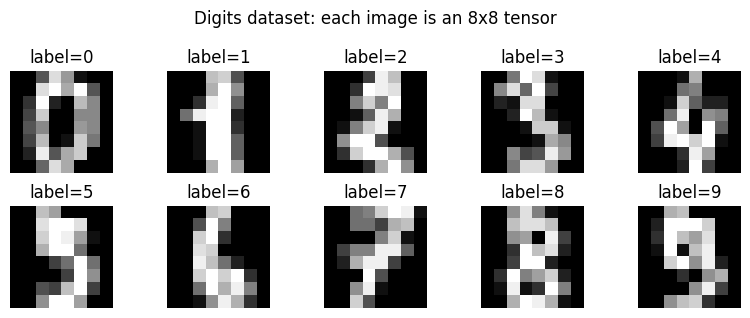

In [2]:
digits = load_digits()
X_digits = digits.data
y_digits = digits.target
images = digits.images

shape_table = pd.DataFrame({
    'Object': ['One label', 'One flattened digit image', 'One 8x8 digit image', 'Batch of 10 digit images', 'Full flattened dataset'],
    'Python object': ['y_digits[0]', 'X_digits[0]', 'images[0]', 'images[:10]', 'X_digits'],
    'Shape': [np.shape(y_digits[0]), X_digits[0].shape, images[0].shape, images[:10].shape, X_digits.shape],
    'Meaning': [
        'scalar target class',
        'vector with 64 pixel features',
        'matrix: 8 rows and 8 columns',
        '3D tensor: 10 images, height 8, width 8',
        'matrix: 1797 rows and 64 features'
    ]
})
display(shape_table)

fig, axes = plt.subplots(2, 5, figsize=(8, 3.2))
for ax, image, label in zip(axes.ravel(), images[:10], y_digits[:10]):
    ax.imshow(image, cmap='gray')
    ax.set_title(f'label={label}')
    ax.axis('off')
plt.suptitle('Digits dataset: each image is an 8x8 tensor')
plt.tight_layout()
plt.show()


### Output Meaning

The digits dataset has 1797 images. Each image can be seen in two ways:

- as an `8 × 8` matrix for humans to view
- as a vector of `64` pixel values for simple models

In larger deep learning image models, images usually use a channel dimension too:

```text
grayscale image: (height, width, 1)
RGB image:       (height, width, 3)
batch of RGB:    (batch_size, height, width, 3)
```

**Common mistake:** students often confuse the sample count with the feature count. In `(1797, 64)`, `1797` is the number of examples and `64` is the number of pixel features per example.


## Step 3: Neural Network Building Blocks

### Neuron

**Definition:** A neuron takes input numbers, multiplies them by weights, adds a bias, then passes the result through an activation function.

Formula:

$$
z = w_1x_1 + w_2x_2 + \dots + w_nx_n + b
$$

Then:

$$
a = f(z)
$$

Where:

- $x$ = input features
- $w$ = weights
- $b$ = bias
- $z$ = weighted sum, often called a logit before output conversion
- $f$ = activation function
- $a$ = neuron output after activation

**Simple intuition:** weights decide how much each input matters. Bias shifts the decision. Activation adds non-linearity.


In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

example = pd.DataFrame({
    'Feature': ['study_hours', 'practice_tests', 'sleep_hours'],
    'Input_x': [4.0, 2.0, 7.0],
    'Weight_w': [0.8, 1.2, 0.3]
})
example['x_times_w'] = example['Input_x'] * example['Weight_w']
bias = -5.0
z = example['x_times_w'].sum() + bias
a = sigmoid(z)

display(example)
print('Bias:', bias)
print('Weighted sum z:', round(z, 3))
print('Sigmoid output a:', round(a, 3))
print('Meaning: this neuron outputs a probability-like value between 0 and 1.')


,Feature,Input_x,Weight_w,x_times_w
0,study_hours,4.0,0.8,3.2
1,practice_tests,2.0,1.2,2.4
2,sleep_hours,7.0,0.3,2.1


Bias: -5.0
Weighted sum z: 2.7
Sigmoid output a: 0.937
Meaning: this neuron outputs a probability-like value between 0 and 1.


### Layer, Network, Parameters, and Hyperparameters

**Layer:** a group of neurons that process the same input.

**Network:** layers connected together.

**Parameters:** values learned from data.

Examples:

- weights
- biases

**Hyperparameters:** choices set before training.

Examples:

- number of layers
- number of neurons per layer
- learning rate
- batch size
- activation function
- optimizer

Common confusion:

```text
weights and biases = learned by training
learning rate and number of layers = chosen by the user
```


## Step 4: Representation Learning

**Definition:** Representation learning means the model learns useful internal versions of the data.

For images, early layers may learn edges. Middle layers may learn shapes. Later layers may learn object parts.

For text, early representations may learn word meaning. Later representations may learn sentence meaning, context, and task-specific signals.

Why hidden layers help:

```text
raw input → simple features → combined features → high-level features → prediction
```

This is the core reason deep learning works well on complex data.


,x1,x2,class
0,-0.122998,1.030699,0
1,1.089153,-0.574213,1
2,0.159448,0.094623,1
3,0.476556,0.835521,0
4,-0.714627,0.166885,0


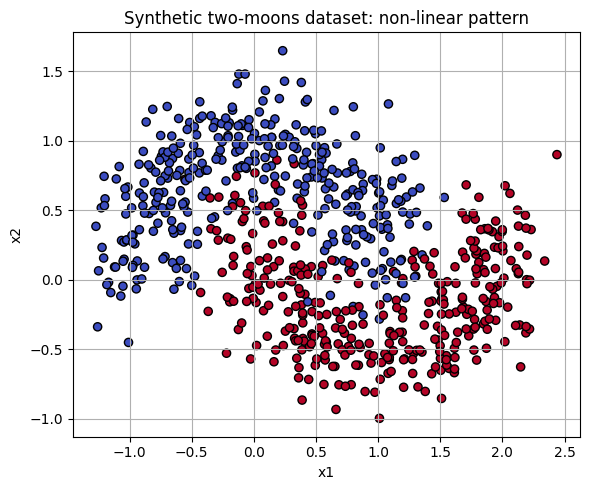

In [4]:
X, y = make_moons(n_samples=700, noise=0.22, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

data_preview = pd.DataFrame(X, columns=['x1', 'x2'])
data_preview['class'] = y
display(data_preview.head())

plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=35)
plt.title('Synthetic two-moons dataset: non-linear pattern')
plt.xlabel('x1')
plt.ylabel('x2')
plt.tight_layout()
plt.show()


### Why this dataset?

The two-moons dataset is useful because a straight line cannot separate the two classes well.

This shows one reason neural networks are useful:

```text
linear model → one straight boundary
neural network with hidden layer → curved/non-linear boundary
```

This does not mean neural networks are always better. It means neural networks can represent more complex functions when the problem needs them.


In [5]:
linear_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(random_state=42))
])

mlp_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', MLPClassifier(
        hidden_layer_sizes=(16, 16),
        activation='relu',
        solver='adam',
        alpha=0.001,
        learning_rate_init=0.01,
        max_iter=1500,
        random_state=42
    ))
])

linear_model.fit(X_train, y_train)
mlp_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)
mlp_pred = mlp_model.predict(X_test)

results = pd.DataFrame({
    'Model': ['Logistic Regression (linear boundary)', 'Small Neural Network / MLP (non-linear boundary)'],
    'Test Accuracy': [accuracy_score(y_test, linear_pred), accuracy_score(y_test, mlp_pred)]
})
display(results.round(3))


,Model,Test Accuracy
0,Logistic Regression (linear boundary),0.871
1,Small Neural Network / MLP (non-linear boundary),0.952


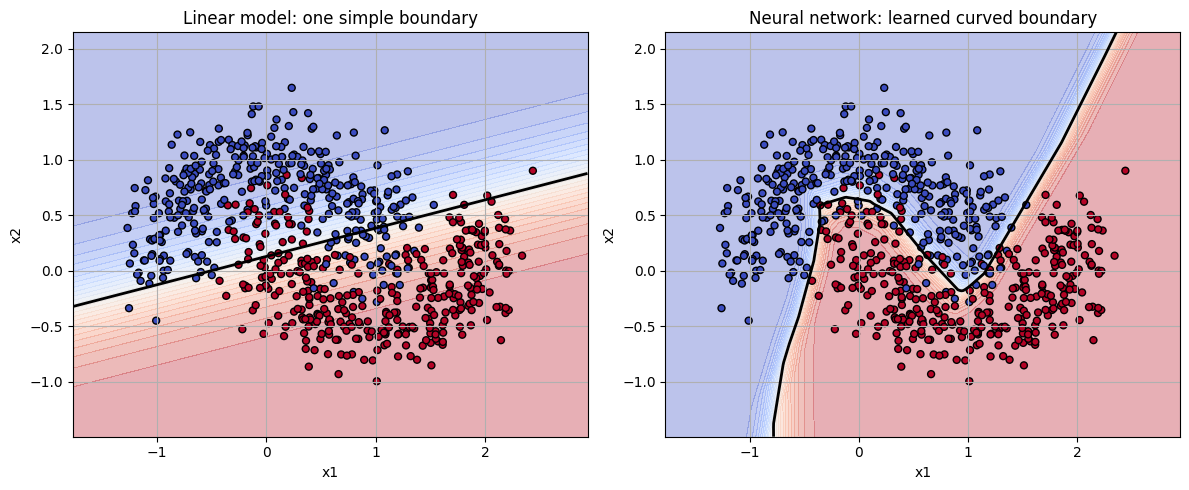

In [6]:
def plot_decision_boundary(model, X, y, title, ax):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    proba = model.predict_proba(grid)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, proba, levels=25, cmap='coolwarm', alpha=0.35)
    ax.contour(xx, yy, proba, levels=[0.5], colors='black', linewidths=2)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=25)
    ax.set_title(title)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_decision_boundary(linear_model, X, y, 'Linear model: one simple boundary', axes[0])
plot_decision_boundary(mlp_model, X, y, 'Neural network: learned curved boundary', axes[1])
plt.tight_layout()
plt.show()


### Output Meaning

The logistic regression model tries to separate the data with one mostly straight boundary. The MLP can bend the boundary because hidden layers and non-linear activations let it combine features in more flexible ways.

What this teaches:

- A neural network is useful when the pattern is complex.
- Hidden layers create intermediate representations.
- Non-linear activations are essential. Without them, stacked layers collapse into another linear model.

Common mistakes:

- Thinking deep learning is always better.
- Using a large neural network for a small simple dataset without validation.
- Looking only at training accuracy and ignoring test accuracy.


## Step 5: Common Deep Learning Tasks

Deep learning is not one algorithm. It is a family of neural-network methods used for many tasks.

| Task | Input | Output | Example |
|---|---|---|---|
| Binary classification | features/image/text | one of two classes | spam vs not spam |
| Multiclass classification | image/text/audio | one class from many | digit 0–9 |
| Multilabel classification | image/text | multiple labels | image has dog + car |
| Regression | features/image | number | house price |
| Object detection | image | boxes + labels | cars in road image |
| Segmentation | image | class per pixel | medical tumor mask |
| Sequence forecasting | time series | future values | sales forecast |
| Recommendation | user/item history | ranked items | movies/products |
| Anomaly detection | sensor/image/logs | anomaly score | machine failure |
| Generation | text/image/audio | new content | image generation |
| Control/RL | state | action | game playing/robotics |

Each task needs a different output layer, loss function, metric, and dataset format.


## Step 6: Why Deep Learning Became Powerful

Deep learning is not new, but it became much more useful because several things improved together.

| Reason | Why it matters |
|---|---|
| More data | Large neural networks need many examples. |
| GPUs/TPUs | Matrix operations became much faster. |
| Better activations | ReLU-like activations reduced vanishing-gradient problems. |
| Better initialization | Xavier/He initialization made training deeper networks easier. |
| Better optimizers | Adam, RMSProp, SGD with momentum improved training stability. |
| Better regularization | Dropout, weight decay, augmentation reduced overfitting. |
| Better architectures | CNNs, LSTMs, Transformers, ResNets solved specific data problems. |
| Better software | PyTorch, TensorFlow, JAX made experimentation easier. |

Deep learning progress came from the combination of data, compute, algorithms, and engineering.


## Step 7: Limitations and Common Mistakes

Deep learning is powerful, but it is not magic.

### Limitations

- Needs more data than many classical ML models.
- Can overfit badly.
- Can be expensive to train.
- Can be hard to interpret.
- Can fail under distribution shift.
- Can learn shortcuts from biased or leaked data.
- Generative models can produce incorrect or hallucinated outputs.

### Beginner Mistakes

| Mistake | Why it is a problem |
|---|---|
| Training without validation | You cannot know if the model generalizes. |
| Using test data during tuning | Causes data leakage. |
| Making the model too large first | Harder to debug and easier to overfit. |
| Ignoring tensor shapes | Most DL errors are shape errors. |
| Not scaling inputs | Training can become slow or unstable. |
| Looking only at accuracy | Some problems need precision, recall, F1, AUC, calibration, or task-specific metrics. |
| Assuming more layers always helps | Deeper models need more care, data, and stabilization. |


## Module 1 Summary

Deep learning is machine learning with neural networks that learn representations from data. The key ideas from this module are:

- Data enters neural networks as tensors.
- A neuron computes weighted input plus bias, then applies activation.
- Layers combine neurons.
- Hidden layers learn intermediate representations.
- Non-linear activations allow neural networks to learn curved/non-linear patterns.
- Deep learning is useful for complex data like images, text, audio, sequences, graphs, and generation.
- Deep learning still needs correct data, validation, metrics, and careful debugging.

Next module: **Math for Deep Learning**, where tensor operations, gradients, probability, entropy, and cross-entropy will be explained deeply.
